<a href="https://colab.research.google.com/github/yami-stack/machine_learning/blob/main/Experiments-ML/CSL701_CE48Machine_Learning_Lab_Exp9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :Yash Manohar Tawate

Batch :CE03


Roll Number :CE48



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

# Manual upload for Google Colab; in Jupyter/local Python, enter the CSV path.
try:
    from google.colab import files
    uploaded = files.upload()  # Choose palmerpenguins_extended.csv
    csv_file = next(
        (name for name in uploaded if name.lower().endswith(".csv")),
        None
    )
    if csv_file is None:
        raise ValueError("Please upload a CSV file.")
except ImportError:
    csv_file = input(
        "Enter the path to palmerpenguins_extended.csv "
        "(or keep the CSV in this notebook's working folder): "
    ).strip().strip('"')
    if not csv_file:
        csv_file = "palmerpenguins_extended.csv"

df = pd.read_csv(csv_file)

print("Dataset loaded successfully.")
print("Shape (rows, columns):", df.shape)
print("\nFirst five rows:")
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())

Saving palmerpenguins_extended.csv to palmerpenguins_extended.csv
Dataset loaded successfully.
Shape (rows, columns): (3430, 11)

First five rows:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021



Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'diet', 'life_stage', 'health_metrics', 'year']

Missing values per column:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
diet                 0
life_stage           0
health_metrics       0
year                 0
dtype: int64


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [2]:
feature_cols = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]
target_col = "species"

# Verify that the expected columns exist before proceeding.
required_cols = feature_cols + [target_col]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Required columns not found in CSV: {missing_cols}")

data = df[required_cols].dropna().copy()
X = data[feature_cols]
y = data[target_col].astype(str)

print("Rows after handling missing values:", len(data))
print("\nSpecies counts:")
print(y.value_counts())
print("\nFeatures (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Rows after handling missing values: 3430

Species counts:
species
Adelie       1560
Gentoo       1247
Chinstrap     623
Name: count, dtype: int64

Features (X) shape: (3430, 4)
Target (y) shape: (3430,)


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (2744, 4)
Testing feature shape: (686, 4)
Training target shape: (2744,)
Testing target shape: (686,)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [5]:
cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)
cart_model.fit(X_train, y_train)

y_pred_cart = cart_model.predict(X_test)
print("CART model trained successfully.")
print("First 10 predictions:", y_pred_cart[:10])

CART model trained successfully.
First 10 predictions: ['Gentoo' 'Gentoo' 'Adelie' 'Adelie' 'Gentoo' 'Gentoo' 'Chinstrap'
 'Adelie' 'Adelie' 'Adelie']


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Accuracy: 0.4519 (45.19%)

CART Confusion Matrix (rows = actual, columns = predicted):
           Adelie  Chinstrap  Gentoo
Adelie        155         64      93
Chinstrap      48         33      44
Gentoo         76         51     122

CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



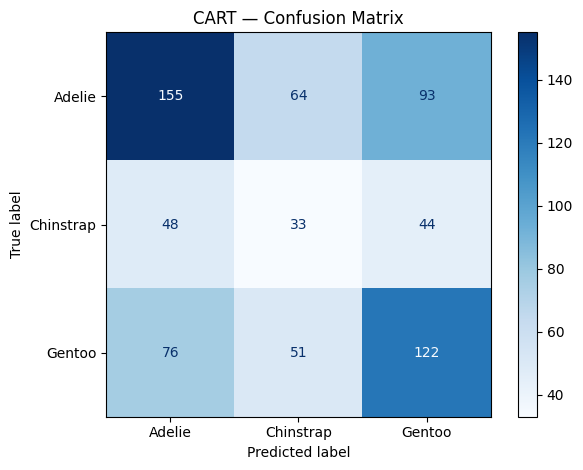

In [6]:
cart_accuracy = accuracy_score(y_test, y_pred_cart)
print(f"CART Accuracy: {cart_accuracy:.4f} ({cart_accuracy * 100:.2f}%)")

labels = sorted(y.unique())
cm_cart = confusion_matrix(y_test, y_pred_cart, labels=labels)
print("\nCART Confusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm_cart, index=labels, columns=labels))

print("\nCART Classification Report:")
print(classification_report(y_test, y_pred_cart, zero_division=0))

ConfusionMatrixDisplay(
    confusion_matrix=cm_cart, display_labels=labels
).plot(cmap="Blues", values_format="d")
plt.title("CART — Confusion Matrix")
plt.tight_layout()
plt.show()

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


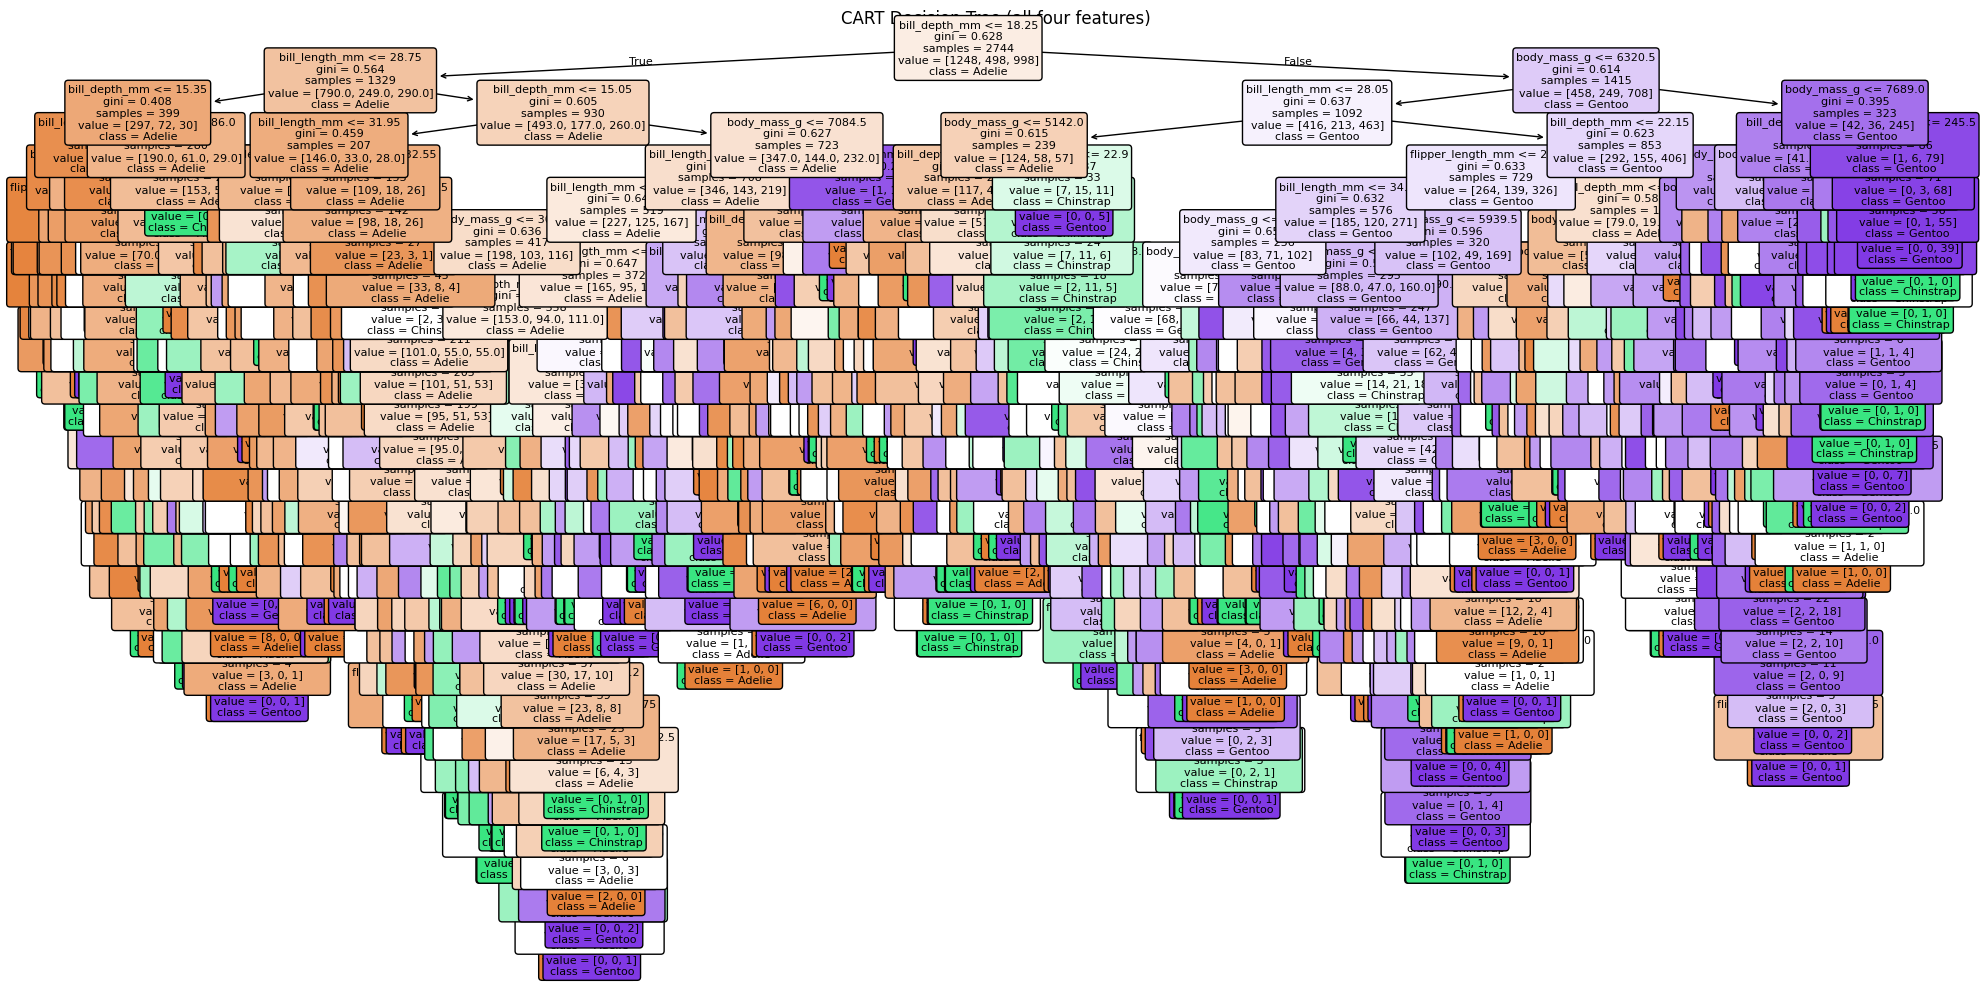

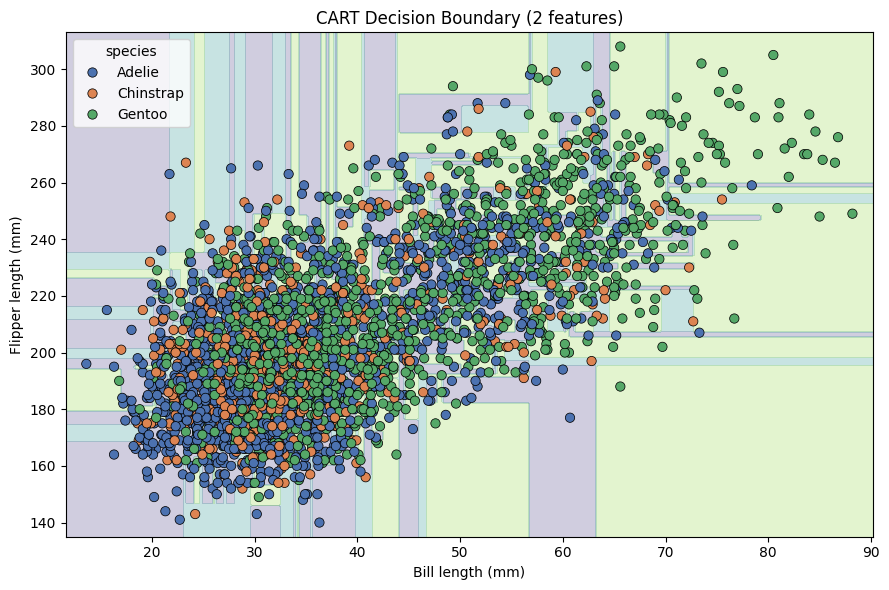

2-feature CART test accuracy: 0.4388


In [7]:
plt.figure(figsize=(20, 10))
plot_tree(
    cart_model,
    feature_names=feature_cols,
    class_names=cart_model.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("CART Decision Tree (all four features)")
plt.tight_layout()
plt.show()

# A 2-feature tree is needed to draw a 2-D decision boundary.
two_features = ["bill_length_mm", "flipper_length_mm"]
X2 = data[two_features]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.20, random_state=42, stratify=y
)
cart_2d = DecisionTreeClassifier(criterion="gini", random_state=42)
cart_2d.fit(X2_train, y2_train)

x_min, x_max = X2[two_features[0]].min() - 2, X2[two_features[0]].max() + 2
y_min, y_max = X2[two_features[1]].min() - 5, X2[two_features[1]].max() + 5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid = pd.DataFrame({
    two_features[0]: xx.ravel(),
    two_features[1]: yy.ravel()
})
Z = cart_2d.predict(grid)
class_to_num = {name: i for i, name in enumerate(cart_2d.classes_)}
Z_num = np.array([class_to_num[v] for v in Z]).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z_num, alpha=0.25, levels=np.arange(len(class_to_num)+1)-0.5, cmap="viridis")
sns.scatterplot(
    data=data, x=two_features[0], y=two_features[1],
    hue=target_col, palette="deep", edgecolor="black", s=45
)
plt.title("CART Decision Boundary (2 features)")
plt.xlabel("Bill length (mm)")
plt.ylabel("Flipper length (mm)")
plt.tight_layout()
plt.show()

print(f"2-feature CART test accuracy: {cart_2d.score(X2_test, y2_test):.4f}")

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

2-feature Logistic Regression accuracy: 0.5262


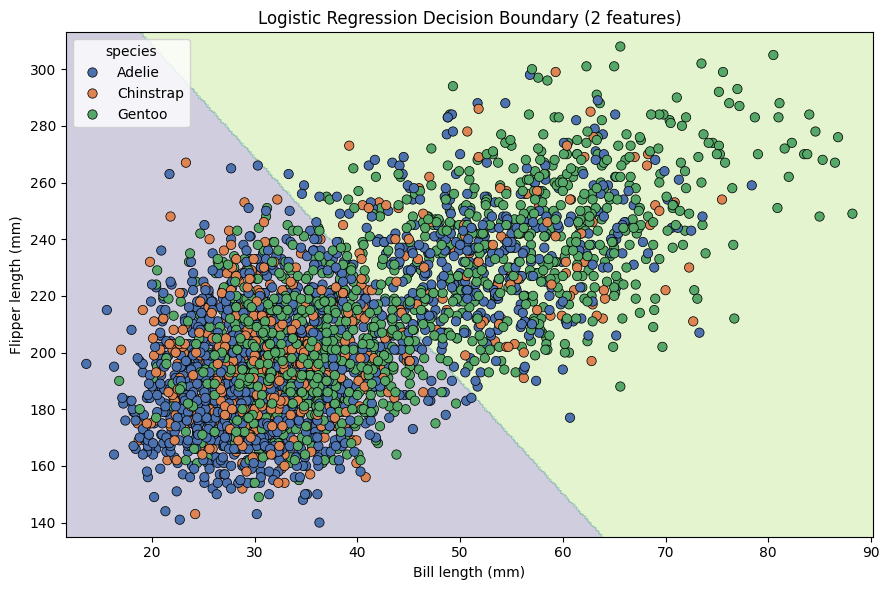

In [8]:
log_model_2d = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)
log_model_2d.fit(X2_train, y2_train)

y_pred_log_2d = log_model_2d.predict(X2_test)
print(f"2-feature Logistic Regression accuracy: {accuracy_score(y2_test, y_pred_log_2d):.4f}")

Z_log = log_model_2d.predict(grid)
Z_log_num = np.array([class_to_num[v] for v in Z_log]).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z_log_num, alpha=0.25, levels=np.arange(len(class_to_num)+1)-0.5, cmap="viridis")
sns.scatterplot(
    data=data, x=two_features[0], y=two_features[1],
    hue=target_col, palette="deep", edgecolor="black", s=45
)
plt.title("Logistic Regression Decision Boundary (2 features)")
plt.xlabel("Bill length (mm)")
plt.ylabel("Flipper length (mm)")
plt.tight_layout()
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

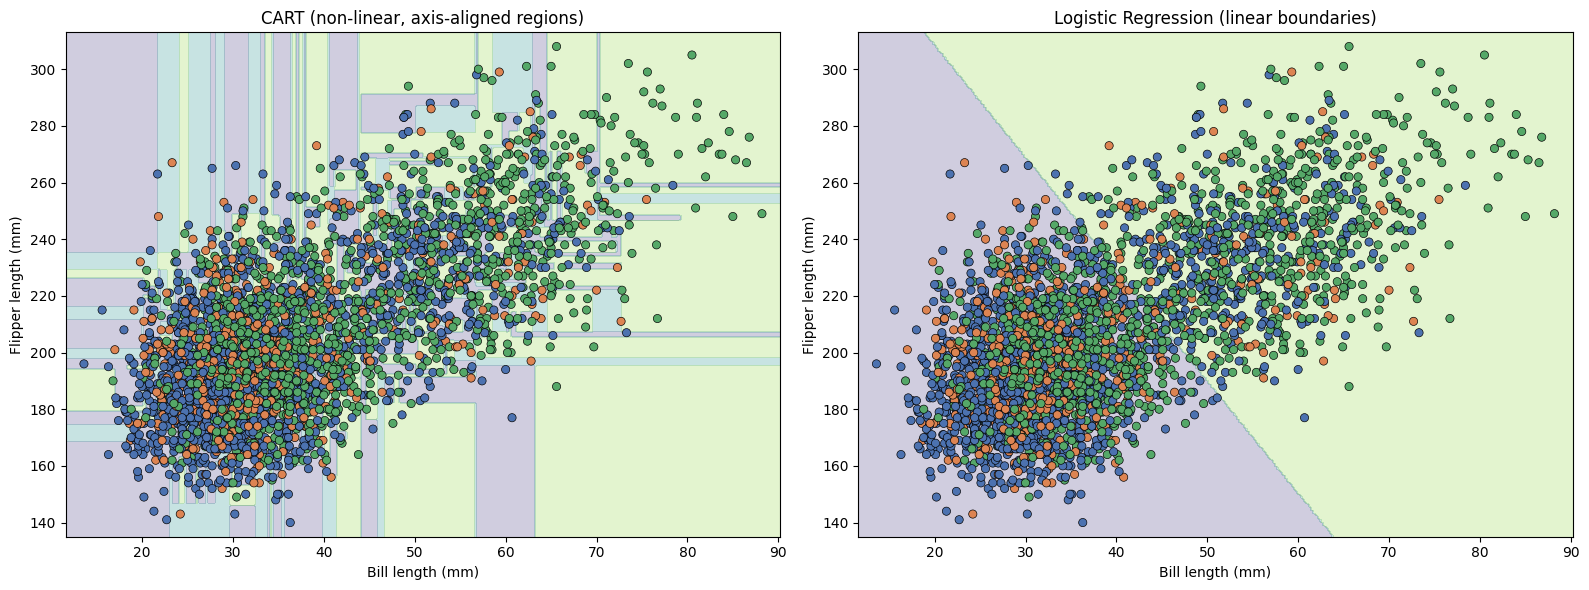

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].contourf(
    xx, yy, Z_num, alpha=0.25,
    levels=np.arange(len(class_to_num)+1)-0.5, cmap="viridis"
)
sns.scatterplot(
    data=data, x=two_features[0], y=two_features[1],
    hue=target_col, palette="deep", edgecolor="black", s=35,
    ax=axes[0], legend=False
)
axes[0].set_title("CART (non-linear, axis-aligned regions)")
axes[0].set_xlabel("Bill length (mm)")
axes[0].set_ylabel("Flipper length (mm)")

axes[1].contourf(
    xx, yy, Z_log_num, alpha=0.25,
    levels=np.arange(len(class_to_num)+1)-0.5, cmap="viridis"
)
sns.scatterplot(
    data=data, x=two_features[0], y=two_features[1],
    hue=target_col, palette="deep", edgecolor="black", s=35,
    ax=axes[1], legend=False
)
axes[1].set_title("Logistic Regression (linear boundaries)")
axes[1].set_xlabel("Bill length (mm)")
axes[1].set_ylabel("Flipper length (mm)")

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

Accuracy comparison:


,Model,Accuracy
0,CART Decision Tree,0.451895
1,Logistic Regression,0.578717



CART Confusion Matrix:
           Adelie  Chinstrap  Gentoo
Adelie        155         64      93
Chinstrap      48         33      44
Gentoo         76         51     122

Logistic Regression Confusion Matrix:
           Adelie  Chinstrap  Gentoo
Adelie        240          0      72
Chinstrap      86          0      39
Gentoo         92          0     157

CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686


Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.57      0.77      0.66       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.59 

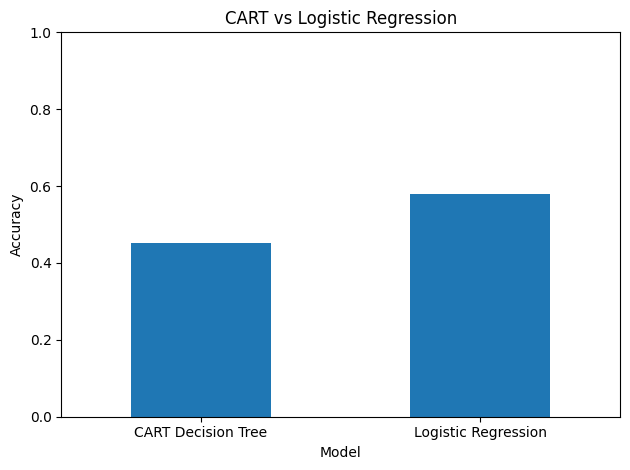

In [10]:
# CART model was trained in Task 4 on all four features.
# Train a scaled Logistic Regression model on those same four features.
log_model_all = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)
log_model_all.fit(X_train, y_train)
y_pred_log = log_model_all.predict(X_test)

results = pd.DataFrame({
    "Model": ["CART Decision Tree", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_cart),
        accuracy_score(y_test, y_pred_log)
    ]
})
print("Accuracy comparison:")
display(results)

print("\nCART Confusion Matrix:")
print(pd.DataFrame(
    confusion_matrix(y_test, y_pred_cart, labels=labels),
    index=labels, columns=labels
))
print("\nLogistic Regression Confusion Matrix:")
print(pd.DataFrame(
    confusion_matrix(y_test, y_pred_log, labels=labels),
    index=labels, columns=labels
))

print("\nCART Classification Report:")
print(classification_report(y_test, y_pred_cart, zero_division=0))
print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, y_pred_log, zero_division=0))

results.plot(x="Model", y="Accuracy", kind="bar", legend=False, ylim=(0, 1), rot=0)
plt.ylabel("Accuracy")
plt.title("CART vs Logistic Regression")
plt.tight_layout()
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.